# PyTorch on FashionMNIST: MLP -> CNN -> Image Regression

This notebook is a guided exercise, not a solved tutorial. Each code cell has:
- **Given code** (imports, data loading, training loop skeleton) so you don't waste time on boilerplate.
- **`# TODO` markers** where you write the actual logic.
- **Hints** in comments right above each TODO — read them before you get stuck, not after.

Structure:
1. **Part 1 — Classification with a plain MLP** (fully-connected network, flattened image)
2. **Part 2 — Classification with a CNN** (conv/pool layers, compare accuracy + param count to Part 1)
3. **Part 3 — Image regression** (predict a continuous value — the rotation angle applied to an image — instead of a class)

Run cells top to bottom. Part 3 depends on the CNN building blocks you write in Part 2.


## Setup

Nothing to write here — just run it. If `torch` isn't installed, uncomment the pip line.

In [1]:
# !pip install torch torchvision --quiet

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset
import torchvision
from torchvision import transforms
import matplotlib.pyplot as plt
import numpy as np

torch.manual_seed(0)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)


Using device: cpu


### Load FashionMNIST (GreyScale)

Given 10 classes of clothing, 28x28 grayscale images. `ToTensor()` scales pixel values to [0, 1]
and gives you a tensor shaped `(1, 28, 28)` — 1 channel since it's grayscale.

In [2]:
transform = transforms.ToTensor()

train_data = torchvision.datasets.FashionMNIST(
    root="./data", train=True, download=True, transform=transform
)
test_data = torchvision.datasets.FashionMNIST(
    root="./data", train=False, download=True, transform=transform
)

classes = train_data.classes
print(classes)
print("Train size:", len(train_data), "| Test size:", len(test_data))
print("One image shape:", train_data[0][0].shape)


['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']
Train size: 60000 | Test size: 10000
One image shape: torch.Size([1, 28, 28])


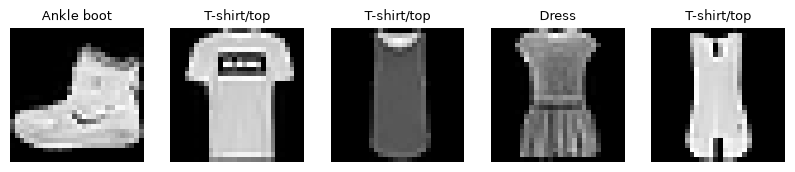

In [3]:
# Sanity check: look at a few images
fig, axes = plt.subplots(1, 5, figsize=(10, 2))
for i, ax in enumerate(axes):
    img, label = train_data[i]
    ax.imshow(img.squeeze(), cmap="gray")
    ax.set_title(classes[label], fontsize=9)
    ax.axis("off")
plt.show()


---
## Part 1 — Classification with a plain MLP (fully connected)

**Goal:** flatten each 28x28 image into a length-784 vector and classify it into one of 10 classes
using only `nn.Linear` layers.

**Architecture to build** (fill in `TODO`s):
```
Input: 1x28x28
-> Flatten -> 784
-> Linear(784, 256) -> ReLU
-> Linear(256, 64)  -> ReLU
-> Linear(64, 10)   (raw logits, no softmax — CrossEntropyLoss applies it internally)
```

**Hint:** `nn.Flatten()` turns `(batch, 1, 28, 28)` into `(batch, 784)`. Put it as the first layer.
**Hint:** Don't apply softmax yourself — `nn.CrossEntropyLoss` expects raw logits and applies
log-softmax internally. Applying softmax twice will hurt training.


In [4]:
class MLPClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 256),
            nn.ReLU(),
            nn.Linear(256, 64),
            nn.ReLU(),
            nn.Linear(64, 10)
        ) # here we define the layers of the network / architecture

    def forward(self, x):
        # TODO: pass x through self.net and return the result
        return self.net(x)


to get some random training images: 

```python
dataiter = iter(trainloader)
images, labels = next(dataiter)
```

via iterator (works like a bookmark); dataloader goes through batches of training data


### Dataloaders (given)

Batching is shared across all three parts, so it's written for you.

In [5]:
batch_size = 64
train_loader = DataLoader(train_data, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_data, batch_size=batch_size, shuffle=False)

model = MLPClassifier().to(device)
print(model)


MLPClassifier(
  (net): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=256, bias=True)
    (2): ReLU()
    (3): Linear(in_features=256, out_features=64, bias=True)
    (4): ReLU()
    (5): Linear(in_features=64, out_features=10, bias=True)
  )
)


### Training loop &mdash; build this yourself

Nothing is given here. Write two functions from scratch: `train_one_epoch` and
`evaluate_classifier`. You'll reuse both, unchanged, in Part 2.

**`train_one_epoch(model, loader, optimizer, loss_fn)` construction guide:**
1. Put the model in training mode.
2. Loop over `(x, y)` batches from `loader`, moving both to `device`.
3. Standard 5-step training step: zero gradients, forward pass, compute loss,
   `.backward()`, optimizer step.
4. Accumulate `loss.item() * x.size(0)` each batch, divide by `len(loader.dataset)` at the
   end, and return that as the average epoch loss.

**`evaluate_classifier(model, loader)` construction guide:**
1. Put the model in eval mode, wrap the function in `torch.no_grad()`.
2. Loop over batches, move to `device`, run `model(x)` to get logits of shape `(batch, 10)`.
3. Convert logits to predicted classes with `.argmax(dim=1)`.
4. Compare to true labels, sum correct predictions and total samples seen.
5. Return `correct / total`.

Write both functions in the cell below.

In [6]:
def train_one_epoch(model, loader, optimizer, loss_fn):
    model.train() # this is prebuilt in pytorch
    for batch in loader:
        x, y = batch
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad() # here we clear 
        outputs = model(x)
        loss = loss_fn(outputs, y)
        loss.backward() # at this point, backpropagation
        optimizer.step()
        optimizer.zero_grad()


def evaluate_classifier(model, loader, loss_fn): # this is the test loop
    
    model.eval()

    size = len(loader.dataset)
    num_batches = len(loader)
    test_loss, correct = 0, 0

    with torch.no_grad():
        for batch in loader:
            x, y = batch
            x, y = x.to(device), y.to(device)
            outputs = model(x)
            test_loss += loss_fn(outputs, y).item()
            correct += (outputs.argmax(1) == y).type(torch.float).sum().item()

    test_loss /= num_batches
    correct /= size
    print(f"Test Error: \n Accuracy: {(100*correct):>0.1f}%, Avg loss: {test_loss:>8f} \n")
    return test_loss, correct



### Train the MLP

**Hint:** `nn.CrossEntropyLoss()` for multi-class classification, `torch.optim.Adam(model.parameters(), lr=1e-3)`
is a reasonable default. 5 epochs should already get you well above 80% test accuracy.

In [ ]:
# TODO: instantiate the model and move it to `device`
mlp_model = MLPClassifier().to(device)

# weights/parameters right after initialization
initial_state = {name: param.detach().clone() for name, param in mlp_model.named_parameters()}
print("Initial parameters:")
for name, param in initial_state.items():
    print(f"  {name:20s} shape={tuple(param.shape)}  mean={param.mean().item():.6f}  std={param.std().item():.6f}")

# TODO: create loss_fn (CrossEntropyLoss) and optimizer (Adam is fine)
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(mlp_model.parameters(), lr=0.001)

n_epochs = 5
for epoch in range(n_epochs):
    print(f"Epoch {epoch+1}\n-------------------------------")
    train_one_epoch(mlp_model, train_loader, optimizer, loss_fn)
    evaluate_classifier(mlp_model, test_loader, loss_fn)


Initial parameters:
  net.1.weight         shape=(256, 784)  mean=0.000016  std=0.020621
  net.1.bias           shape=(256,)  mean=-0.001818  std=0.021232
  net.3.weight         shape=(64, 256)  mean=-0.000032  std=0.036072
  net.3.bias           shape=(64,)  mean=0.008159  std=0.035673
  net.5.weight         shape=(10, 64)  mean=0.006011  std=0.075260
  net.5.bias           shape=(10,)  mean=-0.039172  std=0.062045
Epoch 1
-------------------------------
Test Error: 
 Accuracy: 84.5%, Avg loss: 0.435405 

Epoch 2
-------------------------------


In [ ]:
# compare weights/parameters after training to their initial 
final_state = {name: param.detach().clone() for name, param in mlp_model.named_parameters()}

print("Parameter change after training: ")
for name in initial_state:
    delta = (final_state[name] - initial_state[name]).abs()
    print(f"  {name:20s} mean={final_state[name].mean().item():+.6f}  std={final_state[name].std().item():.6f}  "
          f"| mean|delta|={delta.mean().item():.6f}  max|delta|={delta.max().item():.6f}")

print("\nFirst 5 weights of layer net.1 (Linear 784->256), neuron 0:")
print("  initial:", initial_state["net.1.weight"][0, :5])
print("  trained:", final_state["net.1.weight"][0, :5])


Parameter change after training: 
  net.1.weight         mean=-0.009750  std=0.109846  | mean|delta|=0.073150  max|delta|=1.024741
  net.1.bias           mean=+0.112345  std=0.216771  | mean|delta|=0.182047  max|delta|=0.798139
  net.3.weight         mean=+0.004608  std=0.109244  | mean|delta|=0.063857  max|delta|=0.664062
  net.3.bias           mean=+0.124640  std=0.162225  | mean|delta|=0.149940  max|delta|=0.440361
  net.5.weight         mean=-0.055894  std=0.198873  | mean|delta|=0.108048  max|delta|=0.843250
  net.5.bias           mean=-0.054087  std=0.222722  | mean|delta|=0.165713  max|delta|=0.349695

First 5 weights of layer net.1 (Linear 784->256), neuron 0:
  initial: tensor([ 0.0160, -0.0097,  0.0135,  0.0027, -0.0029])
  trained: tensor([ 0.0356, -0.0740, -0.1477, -0.0504,  0.0179])


In [ ]:
# TODO: count total trainable parameters in mlp_model.
# Hint: sum(p.numel() for p in model.parameters() if p.requires_grad)
mlp_params = sum(p.numel() for p in mlp_model.parameters() if p.requires_grad)
print(f"MLP total parameters: {mlp_params:,}")


MLP total parameters: 218,058


to save a model:

```python

torch.save(model.state_dict(), 'model_weights.pth')

```

to load:

```python

model.load_state_dict(torch.load('model_weights.pth', weights_only=True))
model.eval()

```

Make sure to call model.eval()


---
## Part 2 — Classification with a CNN

**Goal:** same 10-class classification task, but now use conv + pool layers to extract spatial
features before the final dense classifier head — instead of flattening immediately like the MLP did.

**Architecture to build:**
```
Input: 1x28x28
-> Conv2d(in=1,  out=16, kernel=3, padding=1) -> ReLU -> MaxPool2d(2)   # -> 16 x 14 x 14
-> Conv2d(in=16, out=32, kernel=3, padding=1) -> ReLU -> MaxPool2d(2)   # -> 32 x 7 x 7
-> Flatten                                                              # -> 32*7*7 = 1568
-> Linear(1568, 128) -> ReLU
-> Linear(128, 10)                                                      # raw logits
```

**Hints:**
- `padding=1` with a 3x3 kernel keeps spatial size unchanged after the conv (so 28x28 stays 28x28
  before pooling). Without padding, each 3x3 conv shrinks H and W by 2.
- `nn.MaxPool2d(2)` halves both H and W (takes the max value in each 2x2 block).
- Work out the flattened size by hand before writing the Linear layer: after 2 pools, 28 -> 14 -> 7,
  and you have 32 channels, so it's `32 * 7 * 7`.
- Remember from our earlier discussion: each filter looks at *all* incoming channels at once and
  collapses them to one output map — so the second Conv2d's `in_channels` must match the first
  Conv2d's `out_channels` (16), not the original image's 1 channel.


In [ ]:
class CNNClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.kern_net = nn.Sequential(
            nn.Conv2d(in_channels=1, out_channels=16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),          # 28x28 -> 14x14

            nn.Conv2d(in_channels=16, out_channels=32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2)

        )

        # Conv2d take in number of channels, number of out channels (i.e. number of convolutional kernels slid across)

        # MaxPool2d(2) halves both height and width

        self.class_net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(32 * 7 * 7, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )   

        # The Flatten() → Linear() transition is the trickiest part — you must compute the flattened size by hand: channels × height × width after all the convs/pools, and it must exactly match the first Linear's input size, or you'll get a shape-mismatch error at runtime.

    def forward(self, x):
        self.features = self.kern_net(x)
        self.classifier = self.class_net(self.features)
        return self.classifier



If you'd rather access layers by name instead of counting indices, wrap it in nn.Sequential with an OrderedDict:

```python

from collections import OrderedDict

model = nn.Sequential(OrderedDict([
    ("conv1", nn.Conv2d(1, 16, 3, padding=1)),
    ("relu1", nn.ReLU()),
    ("pool1", nn.MaxPool2d(2)),
    ("conv2", nn.Conv2d(16, 32, 3, padding=1)),
    ("relu2", nn.ReLU()),
    ("pool2", nn.MaxPool2d(2)),
    ("flatten", nn.Flatten()),
    ("fc1", nn.Linear(32*7*7, 128)),
    ("relu3", nn.ReLU()),
    ("fc2", nn.Linear(128, 10)),
]))


model.conv1.weight


```


### Train the CNN

Reuses `train_one_epoch` and `evaluate_classifier` from Part 1 — that's the benefit of writing
those generically.

In [ ]:
# TODO: instantiate CNNClassifier, loss_fn, optimizer (same pattern as Part 1)
cnn_model = CNNClassifier().to(device)
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(cnn_model.parameters(), lr=0.001)

n_epochs = 5
for epoch in range(n_epochs):
    print(f"Epoch {epoch+1}\n-------------------------------")
    train_one_epoch(cnn_model, train_loader, optimizer, loss_fn)
    evaluate_classifier(cnn_model, test_loader, loss_fn)


Epoch 1
-------------------------------


Test Error: 
 Accuracy: 86.0%, Avg loss: 0.395336 

Epoch 2
-------------------------------
Test Error: 
 Accuracy: 88.3%, Avg loss: 0.329102 

Epoch 3
-------------------------------
Test Error: 
 Accuracy: 89.0%, Avg loss: 0.302705 

Epoch 4
-------------------------------
Test Error: 
 Accuracy: 89.1%, Avg loss: 0.299059 

Epoch 5
-------------------------------
Test Error: 
 Accuracy: 90.7%, Avg loss: 0.262944 



Note to self: for some reason, CNNs take much longer to train

Need to learn how to implement parallelisation

In [ ]:

cnn_params = sum(p.numel() for p in cnn_model.parameters() if p.requires_grad)

# numel gives total number of elements in a tensor.


print(f"CNN total parameters: {cnn_params:,}")
print(f"MLP total parameters: {mlp_params:,}")


CNN total parameters: 206,922
MLP total parameters: 218,058


---
## Part 3 — Image regression

Classification asks "which of 10 classes is this?" Regression asks "what continuous number does
this image correspond to?" FashionMNIST doesn't ship with a natural continuous label, so we'll
manufacture one that's genuinely useful to predict: **rotate each image by a random angle, and
train a CNN to predict that angle** given only the rotated image.

This means:
- **Input:** a rotated 28x28 image (same as before, still 1 channel)
- **Target:** a single float — the rotation angle in degrees, e.g. `-23.5`
- **Output layer:** 1 linear neuron, no activation
- **Loss:** MSE instead of cross-entropy

### Step 1 — Build a custom Dataset that applies a random rotation and returns the angle

**Hints:**
- Subclass `torch.utils.data.Dataset` and implement `__len__` and `__getitem__`.
- Wrap the existing `train_data` / `test_data` — you don't need to reload FashionMNIST.
- Use `torchvision.transforms.functional.rotate(img_tensor, angle)` to rotate a tensor image.
- Sample the angle uniformly, e.g. `random.uniform(-45, 45)`.
- `__getitem__` should discard the original class label (we don't need it here) and instead
  return `(rotated_image, angle)` where `angle` is a `torch.float32` tensor of shape `(1,)`
  (matching the shape of a single regression output).


In [ ]:
import random
import torchvision.transforms.functional as TF

class RotatedFashionMNIST(Dataset):
    def __init__(self, base_dataset, max_angle=45):
        self.base = base_dataset
        self.max_angle = max_angle

    def __len__(self):
        # TODO: return the number of samples (same as the base dataset)
        pass

    def __getitem__(self, idx):
        img, _label = self.base[idx]  # we ignore the clothing class here

        # TODO: sample a random angle in [-self.max_angle, self.max_angle]
        angle = None

        # TODO: rotate `img` by `angle` using TF.rotate. img is shape (1,28,28).
        rotated_img = None

        # TODO: return (rotated_img, angle_as_float32_tensor_of_shape_[1])
        # Hint: torch.tensor([angle], dtype=torch.float32)
        pass


In [ ]:
# Given: wrap the datasets and build loaders
rot_train_data = RotatedFashionMNIST(train_data)
rot_test_data = RotatedFashionMNIST(test_data)

rot_train_loader = DataLoader(rot_train_data, batch_size=batch_size, shuffle=True)
rot_test_loader = DataLoader(rot_test_data, batch_size=batch_size, shuffle=False)

# Sanity check once your TODOs above are filled in:
sample_img, sample_angle = rot_train_data[0]
print("Rotated image shape:", sample_img.shape, "| angle:", sample_angle)


### Step 2 — Define the regression CNN

Same conv/pool backbone idea as Part 2 — feel free to copy your `CNNClassifier`'s `self.features`
block. The only thing that changes is the head.

**Hints:**
- Final layer: `nn.Linear(128, 1)` — one output number, no activation (linear output), so it can
  represent any real-valued angle including negative ones.
- Do **not** put a softmax, sigmoid, or ReLU on the final output — those would either normalize
  it into [0,1] or clip negative angles to zero, both wrong for this task.


In [ ]:
class CNNRegressor(nn.Module):
    def __init__(self):
        super().__init__()
        # TODO: build the same style conv/pool feature extractor as CNNClassifier
        self.features = None

        # TODO: build the regression head: Flatten -> Linear(1568,128) -> ReLU -> Linear(128,1)
        # (no activation on the very last layer)
        self.regressor = None

    def forward(self, x):
        # TODO: pass through self.features then self.regressor, return result
        pass


### Step 3 — Training loop for regression, build this yourself too

Same overall shape as `train_one_epoch`/`evaluate_classifier`, but two things change:
the loss function becomes MSE, and accuracy doesn't make sense for a continuous target, you'll
report mean absolute error (MAE) in degrees instead.

`train_one_epoch_regression(model, loader, optimizer, loss_fn)` construction guide:
Identical structure to `train_one_epoch` from Part 1: train mode, loop over batches, the same
5-step training step (zero grad, forward, loss, backward, step), accumulate and return the
average loss. The only difference is which `loss_fn` gets passed in (`nn.MSELoss()`), and that
`model(x)` now outputs a single number per sample instead of 10 logits.

`evaluate_regressor(model, loader)` construction guide:
1. Eval mode, `torch.no_grad()`.
2. Loop over batches, get `preds = model(x)`, shape `(batch, 1)`, same shape as `y`.
3. Instead of counting correct/incorrect, measure how far off each prediction is: accumulate
   `(preds - y).abs().sum().item()` across all batches, and separately accumulate the total
   number of samples seen.
4. Return the accumulated absolute error divided by total samples, this is MAE, in the same
   units as the target (degrees).

Write both functions below.

In [ ]:
def train_one_epoch_regression(model, loader, optimizer, loss_fn):
    # TODO: implement per the construction guide above (mirrors train_one_epoch from Part 1)
    pass


def evaluate_regressor(model, loader):
    # TODO: implement per the construction guide above
    pass


In [ ]:
# TODO: instantiate CNNRegressor, MSELoss, and an optimizer
reg_model = None
reg_loss_fn = None
reg_optimizer = None

n_epochs = 5
for epoch in range(n_epochs):
    train_loss = train_one_epoch_regression(reg_model, rot_train_loader, reg_optimizer, reg_loss_fn)
    test_mae = evaluate_regressor(reg_model, rot_test_loader)
    print(f"[Regression] epoch {epoch+1}/{n_epochs}  train_loss={train_loss:.4f}  test_MAE={test_mae:.2f} deg")


### Step 4 — Look at some predictions

Given — just run it once your model trains. Compare the predicted angle to the true angle for a
handful of test images.

In [ ]:
reg_model.eval()
fig, axes = plt.subplots(1, 6, figsize=(14, 3))
with torch.no_grad():
    for i, ax in enumerate(axes):
        img, true_angle = rot_test_data[i]
        pred_angle = reg_model(img.unsqueeze(0).to(device)).item()
        ax.imshow(img.squeeze(), cmap="gray")
        ax.set_title(f"true={true_angle.item():.1f}\npred={pred_angle:.1f}", fontsize=9)
        ax.axis("off")
plt.tight_layout()
plt.show()


---
## Wrap-up questions to think through

1. Compare parameter counts and accuracy between the MLP (Part 1) and CNN (Part 2). What does
   that tell you about weight sharing?
2. In Part 3, why does the final layer have no activation function, while Parts 1 and 2 rely on
   `CrossEntropyLoss` to apply softmax internally?
3. What would happen if you used `nn.MSELoss` on the classification task, or `nn.CrossEntropyLoss`
   on the regression task? (You don't have to run it — reason about the shapes and semantics.)
4. Could you reuse the same `self.features` conv backbone for both classification and regression,
   and only swap the head? Try refactoring Part 2 and Part 3 to share a single feature-extractor
   class as an optional stretch exercise.
